In [1]:
#1: imports et style
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from pyspark.sql import functions as F
from mastodon_utils import get_spark, read_table

spark = get_spark("mastodon-visualisation")

FIG_DIR = "figures" 
os.makedirs(FIG_DIR, exist_ok=True)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"
plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.axisbelow": True,
})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight")
    plt.show()

Spark 3.5.3 prêt - Spark UI : http://localhost:4042


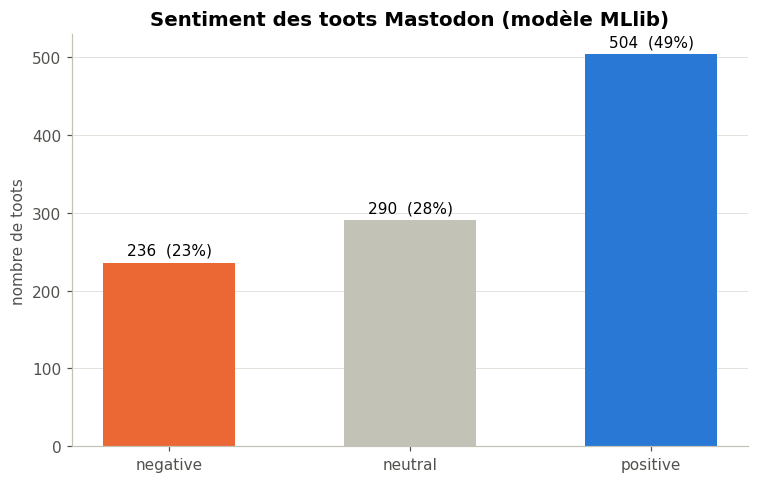

In [2]:
#2: repartition des sentiments
sent = (read_table(spark, "toots_sentiment").groupBy("sentiment").count().toPandas()
        .set_index("sentiment").reindex(["negative", "neutral", "positive"]).fillna(0))

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(sent.index, sent["count"], color=[ORANGE, GREY, BLUE], width=0.55)
ax.bar_label(bars, labels=[f"{int(v)}  ({v / sent['count'].sum():.0%})" for v in sent["count"]], padding=3)
ax.set_title("Sentiment des toots Mastodon (modèle MLlib)")
ax.set_ylabel("nombre de toots")
ax.grid(axis="x", visible=False)
save(fig, "1_sentiment_distribution")

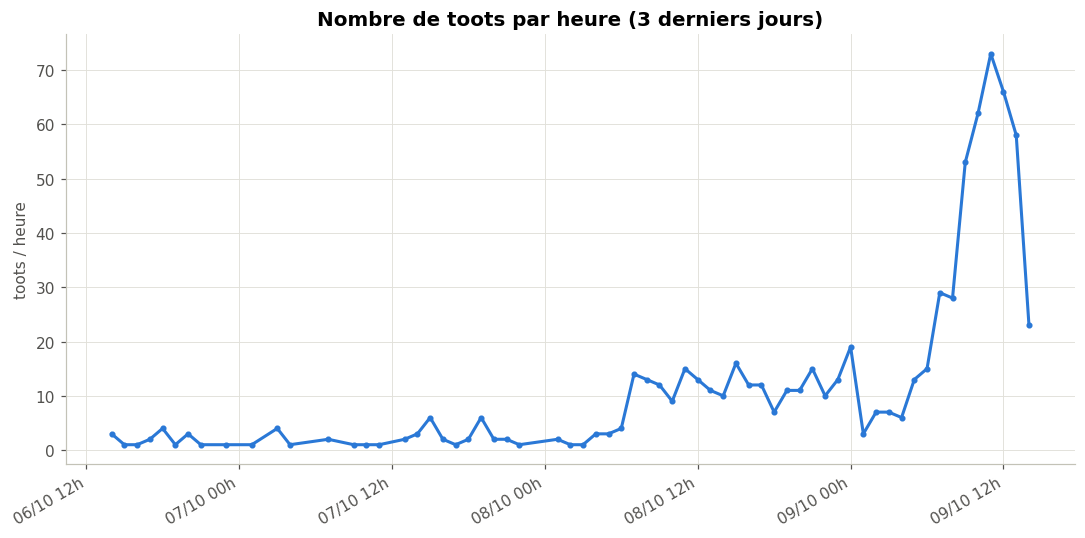

In [3]:
#3: toots par heure 3 derniers jours
toots = read_table(spark, "toots").dropDuplicates(["toot_id"])
last = toots.agg(F.max("event_time")).first()[0]
per_hour = (
    toots.filter(F.col("event_time") >= F.lit(last - pd.Timedelta(days=3))) 
    .groupBy(F.date_trunc("hour", "event_time").alias("hour"))
    .count().orderBy("hour").toPandas()
)

fig, ax = plt.subplots()
ax.plot(per_hour["hour"], per_hour["count"], color=BLUE, linewidth=2, marker="o", markersize=3)
ax.set_title("Nombre de toots par heure (3 derniers jours)")
ax.set_ylabel("toots / heure")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
fig.autofmt_xdate()
save(fig, "2_toots_per_hour")

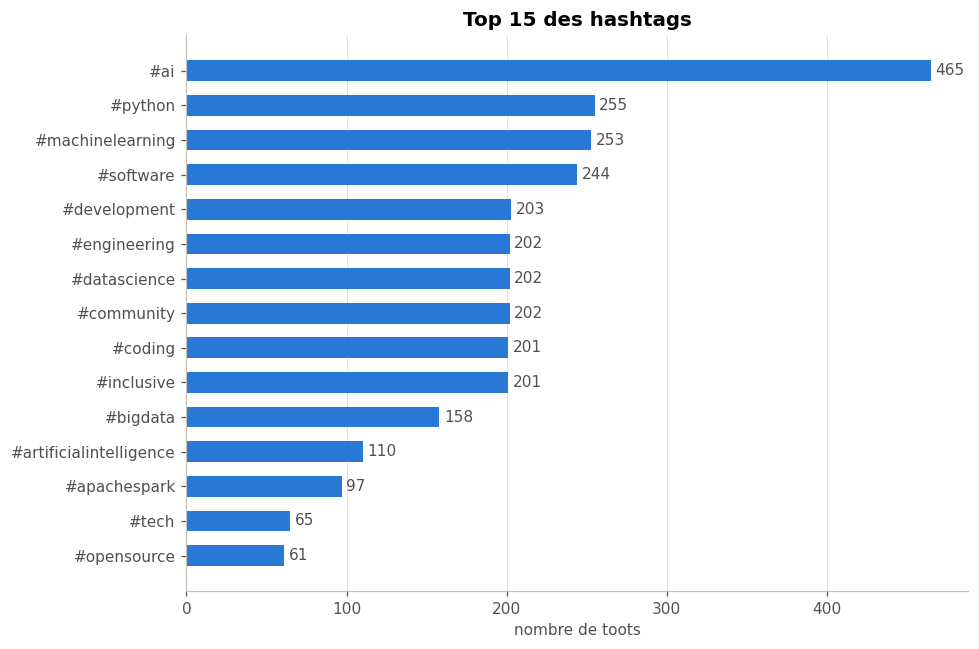

In [4]:
#4: top 15 des hashtags
top = read_table(spark, "batch_top_hashtags").orderBy(F.desc("nb_toots")).limit(15).toPandas()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh("#" + top["hashtag"], top["nb_toots"], color=BLUE, height=0.6)
ax.invert_yaxis() # le plus frequent en haut
ax.bar_label(ax.containers[0], padding=3, color="#52514e")
ax.set_title("Top 15 des hashtags")
ax.set_xlabel("nombre de toots")
ax.grid(axis="y", visible=False)
save(fig, "3_top_hashtags")

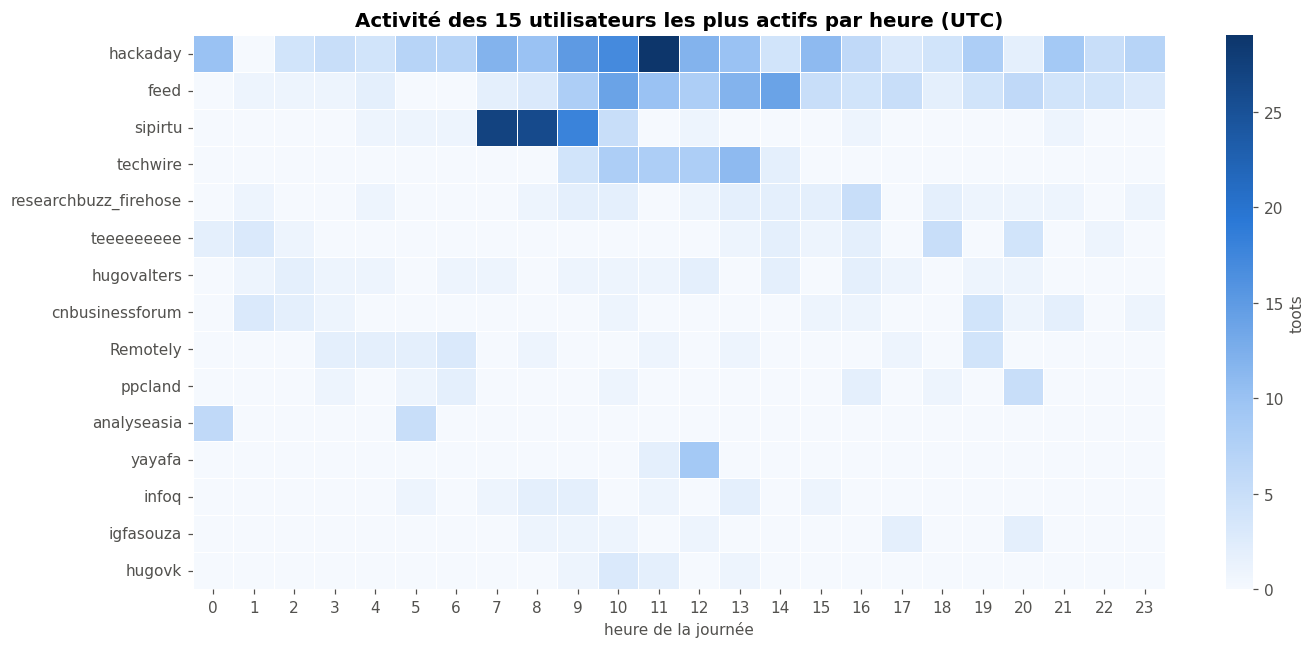

In [5]:
#5: heatmap d activité des utilisateurs
activity = read_table(spark, "batch_user_hour_activity").toPandas()
heat = (activity.pivot_table(index="username", columns="hour", values="nb_toots", aggfunc="sum", fill_value=0)
        .reindex(columns=range(24), fill_value=0))
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index] # les plus actifs en haut

blues = LinearSegmentedColormap.from_list("blues", ["#f5f9fe", "#9ec5f4", "#2a78d6", "#0d366b"])
fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(heat, cmap=blues, linewidths=0.5, linecolor="white", cbar_kws={"label": "toots"}, ax=ax)
ax.set_title("Activité des 15 utilisateurs les plus actifs par heure (UTC)")
ax.set_xlabel("heure de la journée")
ax.set_ylabel("")
save(fig, "4_user_activity_heatmap")

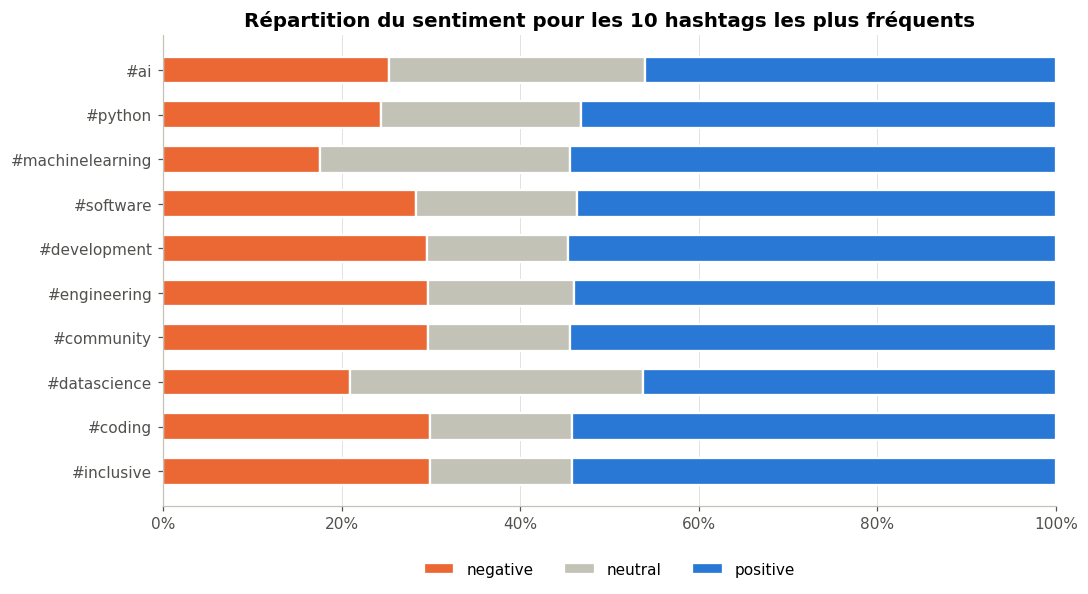

In [6]:
#6: sentiment par hashtag
by_tag = (
    read_table(spark, "toots_sentiment")
    .withColumn("hashtag", F.explode(F.split("hashtags", ",")))
    .filter(F.col("hashtag") != "")
    .groupBy("hashtag", "sentiment").count().toPandas()
    .pivot_table(index="hashtag", columns="sentiment", values="count", fill_value=0)
    .reindex(columns=["negative", "neutral", "positive"], fill_value=0)
)
by_tag = by_tag.loc[by_tag.sum(axis=1).sort_values(ascending=False).index[:10]]
share = by_tag.div(by_tag.sum(axis=1), axis=0) 

fig, ax = plt.subplots(figsize=(10, 5.5))
left = 0
for col, color in [("negative", ORANGE), ("neutral", GREY), ("positive", BLUE)]:
    ax.barh("#" + share.index, share[col], left=left, color=color, label=col, height=0.6,
            edgecolor="white", linewidth=1.5)
    left = left + share[col]
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(0, 1)
ax.set_title("Répartition du sentiment pour les 10 hashtags les plus fréquents")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.18), frameon=False)
ax.grid(axis="y", visible=False)
save(fig, "5_sentiment_by_hashtag")

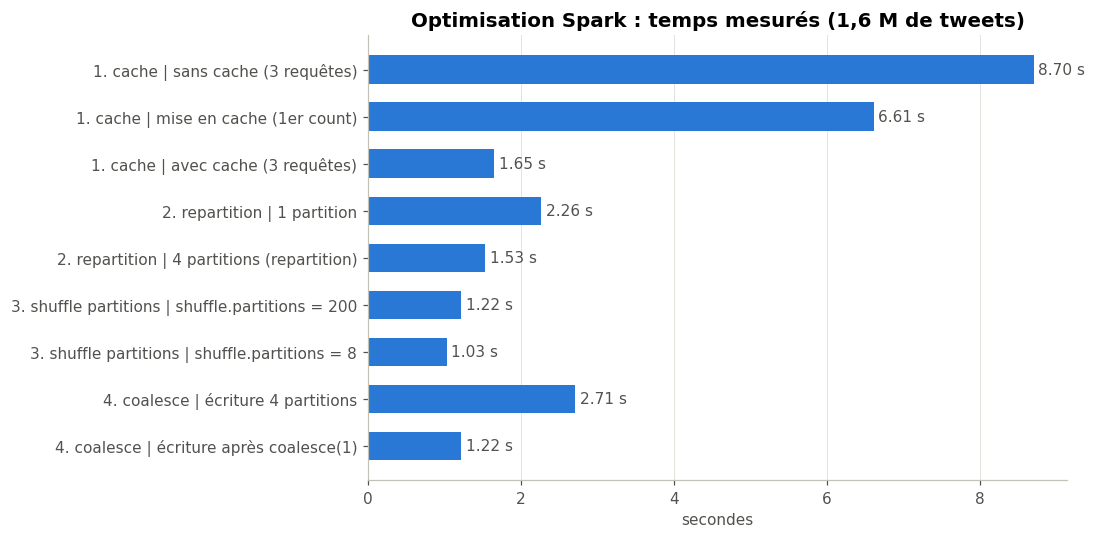

In [7]:
#7: résultats de l optimisation
bench = read_table(spark, "batch_benchmark").toPandas()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(bench["experiment"] + " | " + bench["label"], bench["seconds"], color=BLUE, height=0.6)
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt="%.2f s", padding=3, color="#52514e")
ax.set_title("Optimisation Spark : temps mesurés (1,6 M de tweets)")
ax.set_xlabel("secondes")
ax.grid(axis="y", visible=False)
save(fig, "6_optimisation_benchmark")